# 1 Environment Setup

In [1]:
import sys
from pathlib import Path
project_root = Path.cwd().resolve().parent
sys.path.insert(0, str(project_root))
print(f"Using project root: {project_root}\n Please verify path is correct.")
print("Not required if package installed in editable mode via 'pip install -e .'")

Using project root: /home/mbz/Documents/PhD
 Please verify path is correct.
Not required if package installed in editable mode via 'pip install -e .'


In [2]:
from src.config import PipelineConfig
from src.pipeline import SensorPipeline
from src.logging_utils import setup_logging
config = PipelineConfig.from_yaml(Path("config/sensors.yaml"))
print(f"Loaded {len(config.sensors)} sensors:")
for s in config.sensors:
    print(f"  - {s.name} ({s.sensor_type}, altitude: {s.altitude_m}m)")
setup_logging(config.log_dir, log_name="notebook_run")
pipeline = SensorPipeline(config, force=False)

2026-03-03 10:30:14,559 - root - INFO - Logging initialized. Log file: /home/mbz/Documents/PhD/SCD41_DATA/output/logs/notebook_run_20260303_103014.log


Loaded 5 sensors:
  - CO2_SCT1_2M (scd41, altitude: 2m)
  - CO2_30M_A (scd41, altitude: 30m)
  - CO2_30M_B (scd41, altitude: 30m)
  - CO2_30M_C (scd41, altitude: 30m)
  - LGR_30M (lgr_csv, altitude: 30m)


# 2 Process Raw Measurements

### todo:
- collect, process 2025 11, 12 raw data from smear

In [ ]:
# process 2024 9-12
for mo in [9, 10, 11, 12]:
    print(f"\n{'='*30}")
    print(f"Processing Year {2024} | Month {mo:02d}")
    print(f"{'='*30}")
    pipeline.run_all(year=2024, month=mo)

In [ ]:
# process 2025
for mo in [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]:
    print(f"\n{'='*30}")
    print(f"Processing Year {2025} | Month {mo:02d}")
    print(f"{'='*30}")
    pipeline.run_all(year=2025, month=mo)

In [ ]:
# process 2026 1, 2
for mo in [1, 2]:
    print(f"\n{'='*30}")
    print(f"Processing Year {2026} | Month {mo:02d}")
    print(f"{'='*30}")
    pipeline.run_all(year=2026, month=mo)

In [ ]:
# process 2024 - 2026
for yr in [2024, 2025, 2026]:
    for mo in [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]:
        print(f"\n{'='*30}")
        print(f"Processing Year {yr} | Month {mo:02d}")
        print(f"{'='*30}")
        pipeline.run_all(year=yr, month=mo)

### Check for Duplicates

In [3]:
import pandas as pd
# Check for duplicates in individual CSVs
for sensor in ['CO2_SCT1_2M', 'CO2_30M_A', 'CO2_30M_B', 'CO2_30M_C']:
    df = pd.read_csv(f'output/sensors/{sensor}/csv/{sensor}_10min.csv', parse_dates=['timestamp'])
    dups = df['timestamp'].duplicated().sum()
    print(f"{sensor}: {dups} duplicates")

CO2_SCT1_2M: 0 duplicates
CO2_30M_A: 0 duplicates
CO2_30M_B: 0 duplicates
CO2_30M_C: 0 duplicates


# 3 Merge Sensor Data

## maybe for v0.3.0: Merged output consolidation

> Target: after pipeline output format stabilises (post v0.2.0 per-sensor refactor)

### Planned changes to `output/merged/`

Current structure:

```
merged/
├── csv/          # monthly merged CSVs + total merged CSV
└── parquet/      # monthly merged Parquets (no total)
```

Proposed:

```
merged/
├── csv/
│   ├── SMEAR_EE_CO2_2024_09_merged.csv
│   ├── ...
│   └── SMEAR_EE_CO2_merged.csv          # (exists) total combined
├── parquet/
│   ├── SMEAR_EE_CO2_2024_09_merged.parquet
│   ├── ...
│   └── SMEAR_EE_CO2_merged.parquet      # TODO: total combined parquet
└── uptime/
    └── SMEAR_EE_CO2_uptime.parquet      # TODO: all sensors, all months
```

### Rationale
- **Total combined parquet**: mirrors the existing total CSV; single-read 
  for analysis notebooks and vis package (columnar compression, faster I/O)
- **Combined uptime parquet**: single file with `sensor_id` column; replaces 
  per-sensor CSV reads in `UptimePlots`; enables one-load-filter-plot pattern
- Vis package refactored to consume these two files instead of per-sensor CSVs

### Dependencies
- Requires stable per-sensor directory structure (v0.2.0)
- Vis package update is downstream — only refactor after merged outputs settle

In [4]:
from src.merger import merge_all_sensors

merged = merge_all_sensors(config=config)

print(f"Merged dataset shape: {merged.shape}")
print(f"Date range: {merged.index.min()} to {merged.index.max()}")
print(f"\nColumns: {list(merged.columns)}")

2026-03-03 10:30:26,774 - src.merger - INFO - Merging 5 sensors...
2026-03-03 10:30:26,775 - src.merger - INFO -   Loading CO2_SCT1_2M...
2026-03-03 10:30:26,890 - src.merger - INFO -     66799 rows (2024-09-12 12:20:00 to 2025-12-28 07:00:00)
2026-03-03 10:30:26,891 - src.merger - INFO -   Loading CO2_30M_A...
2026-03-03 10:30:26,938 - src.merger - INFO -     34954 rows (2024-09-19 11:10:00 to 2026-02-03 23:50:00)
2026-03-03 10:30:26,939 - src.merger - INFO -   Loading CO2_30M_B...
2026-03-03 10:30:26,998 - src.merger - INFO -     28902 rows (2024-09-19 11:10:00 to 2026-02-18 14:30:00)
2026-03-03 10:30:26,999 - src.merger - INFO -   Loading CO2_30M_C...
2026-03-03 10:30:27,097 - src.merger - INFO -     61992 rows (2024-10-02 09:30:00 to 2026-02-18 14:30:00)
2026-03-03 10:30:27,098 - src.merger - INFO -   Loading LGR_30M...
2026-03-03 10:30:27,665 - src.merger - INFO -     111053 rows (2024-01-01 00:00:00 to 2026-02-18 14:50:00)
2026-03-03 10:30:27,666 - src.merger - INFO -   Merging o

Merged dataset shape: (111747, 101)
Date range: 2024-01-01 00:00:00 to 2026-02-18 14:50:00

Columns: ['co2_sct1_2m_co2_mean', 'co2_sct1_2m_co2_std', 'co2_sct1_2m_co2_count', 'co2_sct1_2m_temp_mean', 'co2_sct1_2m_temp_std', 'co2_sct1_2m_temp_count', 'co2_sct1_2m_humidity_mean', 'co2_sct1_2m_humidity_std', 'co2_sct1_2m_humidity_count', 'co2_sct1_2m_co2_qc', 'co2_sct1_2m_temp_qc', 'co2_sct1_2m_humidity_qc', 'co2_30m_a_co2_mean', 'co2_30m_a_co2_std', 'co2_30m_a_co2_count', 'co2_30m_a_temp_mean', 'co2_30m_a_temp_std', 'co2_30m_a_temp_count', 'co2_30m_a_humidity_mean', 'co2_30m_a_humidity_std', 'co2_30m_a_humidity_count', 'co2_30m_a_co2_qc', 'co2_30m_a_temp_qc', 'co2_30m_a_humidity_qc', 'co2_30m_b_co2_mean', 'co2_30m_b_co2_std', 'co2_30m_b_co2_count', 'co2_30m_b_temp_mean', 'co2_30m_b_temp_std', 'co2_30m_b_temp_count', 'co2_30m_b_humidity_mean', 'co2_30m_b_humidity_std', 'co2_30m_b_humidity_count', 'co2_30m_b_co2_qc', 'co2_30m_b_temp_qc', 'co2_30m_b_humidity_qc', 'co2_30m_c_co2_mean', 'co2_3

# 4 Validate Data

In [5]:
from src.validation import validate_outputs
validate_outputs()

/home/mbz/Documents/PhD/SCD41_DATA/src/validation/checks.py:446: DtypeWarning: Columns (10,11,12,22,23,24,34,35,36,46,47,48) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(merged_csv, parse_dates=['timestamp'])
/home/mbz/Documents/PhD/SCD41_DATA/src/validation/checks.py:542: DtypeWarning: Columns (10,11,12,22,23,24,34,35,36,46,47,48) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(merged_csv, parse_dates=['timestamp'])
2026-03-03 10:30:48,079 - src.validation - INFO -   JSON report: /home/mbz/Documents/PhD/SCD41_DATA/output/validation/validation_report.json
2026-03-03 10:30:48,107 - src.validation - INFO -   Markdown receipt: /home/mbz/Documents/PhD/SCD41_DATA/output/validation/VALIDATION_RECEIPT.md



SMEAR ESTONIA CO2 DATA VALIDATION RECEIPT
Generated: 2026-03-03T10:30:43.740332
Sensors dir:      /home/mbz/Documents/PhD/SCD41_DATA/output/sensors
Merged dir:       /home/mbz/Documents/PhD/SCD41_DATA/output/merged
Year-month range: 2024-01 to 2026-02

1. COLUMN NAME VALIDATION
------------------------------------------------------------
  │ Verifies column names are clean Python identifiers.
  │ Checks for '<lambda>' artifacts from pandas aggregation bugs.
  │ PASS = no problematic column names found..
  │
  │ Status: ✓ ALL PASSED (5/5)
  └──────────────────────────────────────────────────
    ✓ CO2_30M_A/CO2_30M_A_10min.csv: Clean
    ✓ CO2_30M_B/CO2_30M_B_10min.csv: Clean
    ✓ CO2_30M_C/CO2_30M_C_10min.csv: Clean
    ✓ CO2_SCT1_2M/CO2_SCT1_2M_10min.csv: Clean
    ✓ LGR_30M/LGR_30M_10min.csv: Clean

2. FILE INVENTORY
------------------------------------------------------------
  │ Confirms CSV and Parquet files exist for each sensor/month.
  │ PASS = matching CSV and Parquet counts

# 5 Plot

### todo:
 - fix taylor plot
 - add options for different time resolutions (hourly, daily)?
 - add options for different date ranges?
 - include temp hue for raw timeseries
 - compound lgr v A,B,C,2m timeseries w/ temp/rh
 - compound lgr v A,B,C,2m uptime? w/ temp/rh
 - refactor validation_plots.py: 
   - inherit single pd read_csv... (try read parquet?; for v0.2.0? --optional... works)

In [6]:
from src.visualization import generate_all_plots
# generate_all_plots(config, show=False, exclude=['scatter','uptime','co2','qc','monthly','comparison','difference','taylor'])
# generate_all_plots(config, show=False, exclude=['scatter', 'co2','uptime','monthly','comparison','difference','taylor'])
generate_all_plots(config, show=False, exclude=['taylor'])
# quiet — save only
# Exclude categories: 'uptime', 'qc', 'co2', 'monthly', 'uptime_summary', 'comparison', 'scatter', 'difference', 'taylor', 'scatter_hue', 'timeseries_hue'

2026-03-03 10:31:01,135 - src.visualization - INFO - Generating plots...
2026-03-03 10:31:01,137 - src.visualization - INFO -   CO2_SCT1_2M: Uptime timeseries
2026-03-03 10:31:01,515 - UptimePlots - INFO - Saved: CO2_SCT1_2M_uptime_timeseries.png
2026-03-03 10:31:01,515 - src.visualization - INFO -   CO2_SCT1_2M: Uptime heatmap
2026-03-03 10:31:02,073 - UptimePlots - INFO - Saved: CO2_SCT1_2M_uptime_heatmap.png
2026-03-03 10:31:02,074 - src.visualization - INFO -   CO2_SCT1_2M: QC summary
2026-03-03 10:31:02,161 - QualityControlPlots - INFO - Using coverage JSON for CO2_SCT1_2M
2026-03-03 10:31:02,591 - QualityControlPlots - INFO - Saved: CO2_SCT1_2M_qc_summary.png
2026-03-03 10:31:02,593 - src.visualization - INFO -   CO2_SCT1_2M: CO2 timeseries (full)
2026-03-03 10:31:03,217 - ValidationPlots - INFO - Saved: CO2_SCT1_2M_co2_timeseries_full.png
2026-03-03 10:31:03,220 - src.visualization - INFO -   CO2_SCT1_2M: CO2 timeseries (2024_09)
2026-03-03 10:31:03,655 - ValidationPlots - INFO 

### Processed Measurements Plot

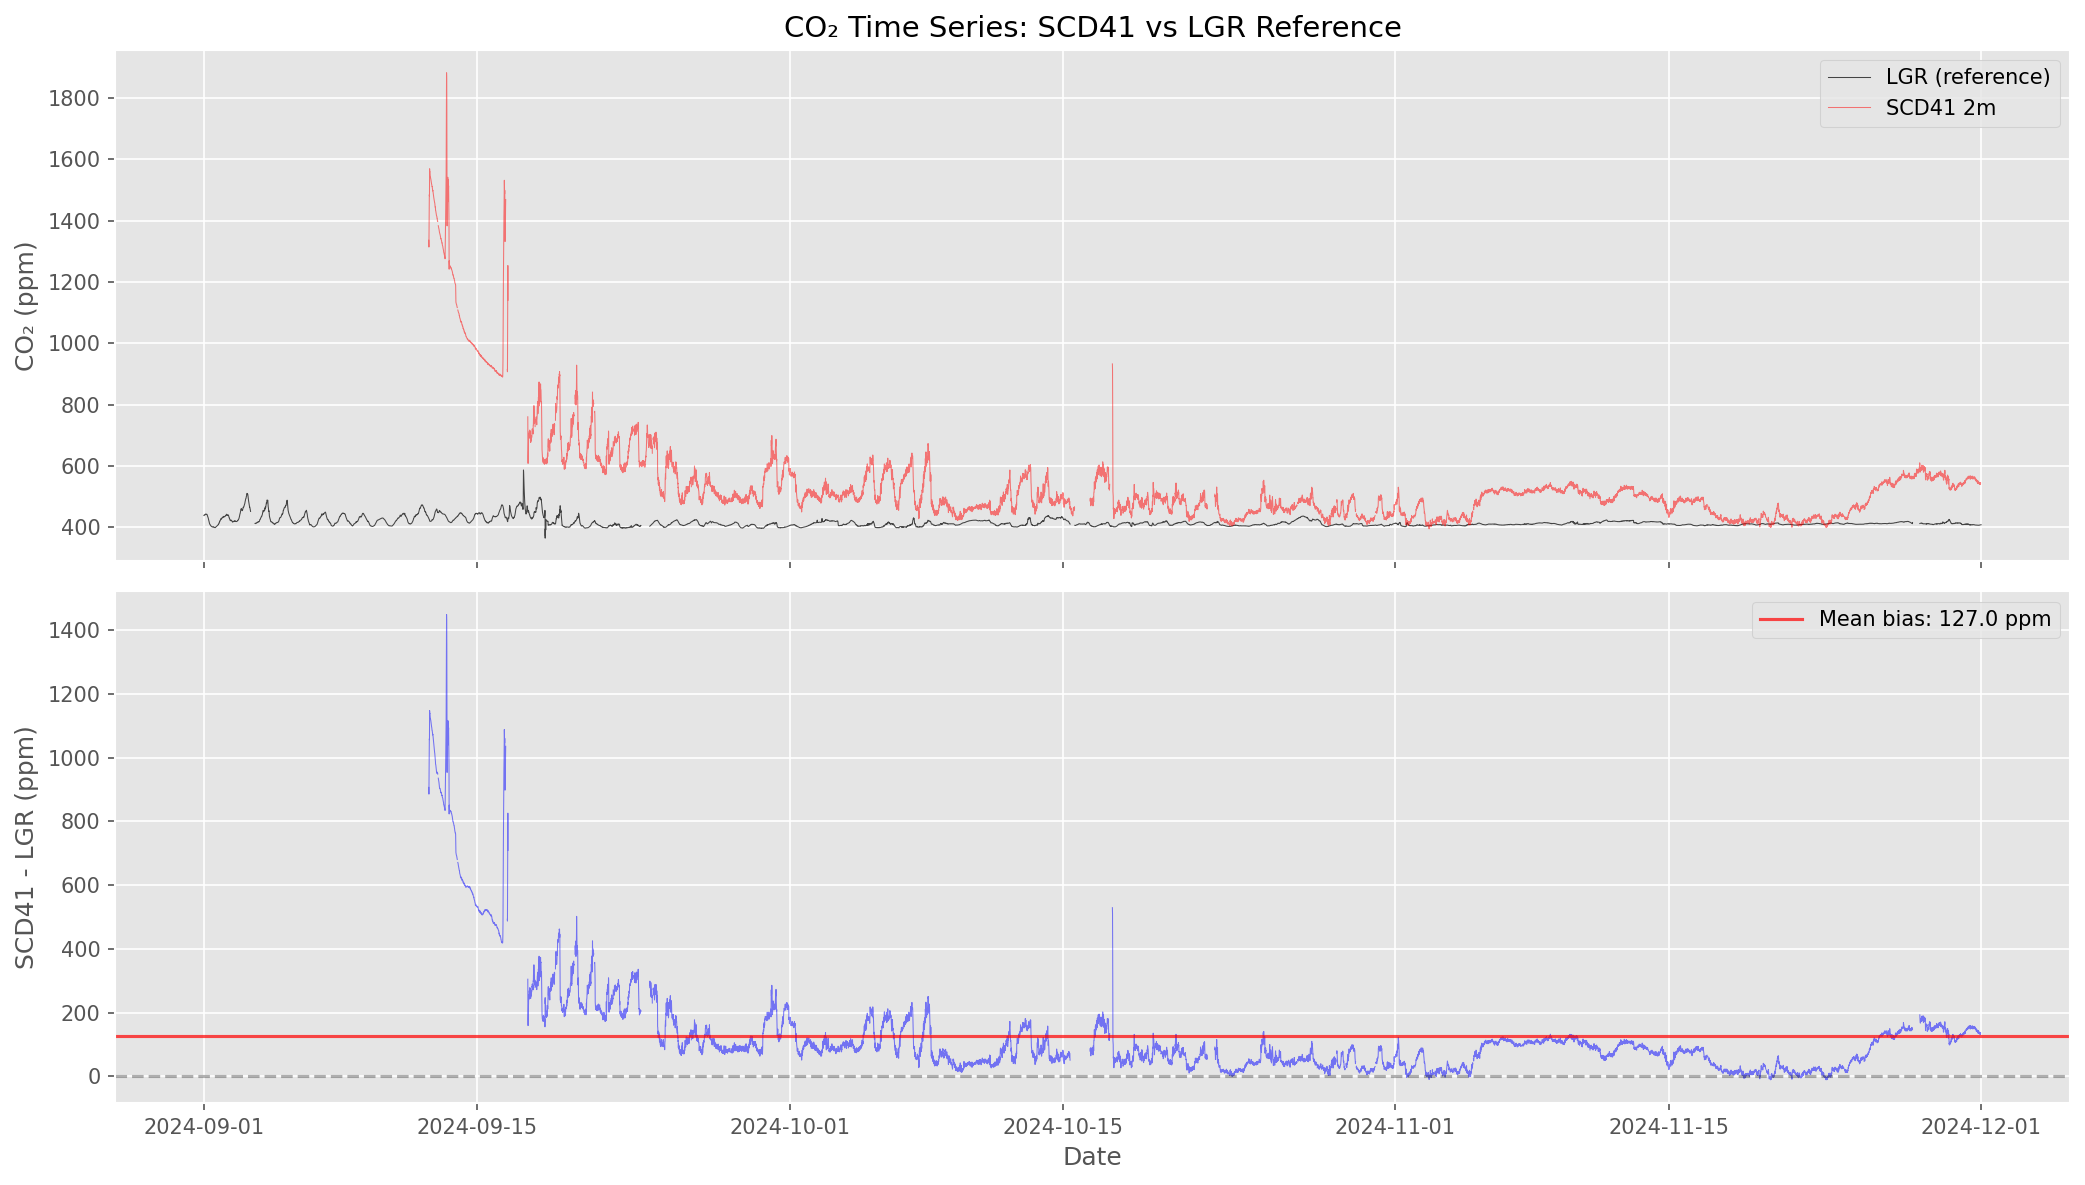

Mean bias: 127.0 ppm
RMSE: 204.6 ppm
Correlation: 0.519


In [8]:
import matplotlib.pyplot as plt
import pandas as pd

merged = pd.read_csv('output/merged/csv/SMEAR_EE_CO2_merged.csv', parse_dates=['timestamp'])

# Quick comparison: SCD41 2m vs LGR reference
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Time series
ax1 = axes[0]
ax1.plot(merged['timestamp'], merged['lgr_30m_CO2_dry_mean'], 'k-', alpha=0.7, label='LGR (reference)', linewidth=0.5)
ax1.plot(merged['timestamp'], merged['co2_sct1_2m_co2_mean'], 'r-', alpha=0.5, label='SCD41 2m', linewidth=0.5)
ax1.set_ylabel('CO₂ (ppm)')
ax1.legend()
ax1.set_title('CO₂ Time Series: SCD41 vs LGR Reference')

# Difference
ax2 = axes[1]
diff = merged['co2_sct1_2m_co2_mean'] - merged['lgr_30m_CO2_dry_mean']
ax2.plot(merged['timestamp'], diff, 'b-', alpha=0.5, linewidth=0.5)
ax2.axhline(0, color='k', linestyle='--', alpha=0.3)
ax2.axhline(diff.mean(), color='r', linestyle='-', alpha=0.7, label=f'Mean bias: {diff.mean():.1f} ppm')
ax2.set_ylabel('SCD41 - LGR (ppm)')
ax2.set_xlabel('Date')
ax2.legend()

plt.tight_layout()
plt.savefig('output/merged/plots/quick_comparison.png', dpi=300)
plt.show()

print(f"Mean bias: {diff.mean():.1f} ppm")
print(f"RMSE: {(diff**2).mean()**0.5:.1f} ppm")
print(f"Correlation: {merged['co2_sct1_2m_co2_mean'].corr(merged['lgr_30m_CO2_dry_mean']):.3f}")

### taylor plot dev

In [54]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.projections import PolarAxes
import mpl_toolkits.axisartist.grid_finder as gf
import mpl_toolkits.axisartist.floating_axes as fa


class TaylorDiagram:
    """Taylor diagram using floating-axes polar projection.

    After Taylor (2001), J. Geophys. Res., 106(D7), 7183–7192.
    Uses mpl_toolkits.axisartist for proper axis formatting.

    Automatically extends to a semicircle when any correlation
    value is negative, so the diagram always fits the data.
    """

    def __init__(self, STD, fig=None, rect=111, label='_', smax=None,
                 extend_negative=False):
        """
        Args:
            STD:   Reference standard deviation
            fig:   Existing figure or None
            rect:  Subplot spec
            label: Reference point legend label
            smax:  Manual axis limit (default: 1.5 * STD)
            extend_negative: If True, show full semicircle (r = -1 to 1).
                             Use from_stats() to set this automatically.
        """
        self.STD = STD
        self.extend_negative = extend_negative
        tr = PolarAxes.PolarTransform(apply_theta_transforms=False)

        # Correlation tick positions
        rlocs_pos = np.array([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6,
                              0.7, 0.8, 0.9, 0.95, 0.99, 1.0])
        if extend_negative:
            rlocs_neg = np.array([-0.2, -0.4, -0.6, -0.8, -0.99])
            rlocs = np.concatenate((rlocs_neg[::-1], rlocs_pos))
            theta_max = np.pi
        else:
            rlocs = rlocs_pos
            theta_max = np.pi / 2

        tlocs = np.arccos(rlocs)
        gl1 = gf.FixedLocator(tlocs)
        tf1 = gf.DictFormatter(dict(zip(tlocs, map(str, rlocs))))

        self.smin = 0.001  # avoid duplicate 0.0 label at origin
        self.smax = smax if smax is not None else 1.5 * self.STD
        self.theta_max = theta_max

        gh = fa.GridHelperCurveLinear(
            tr,
            extremes=(0, theta_max, self.smin, self.smax),
            grid_locator1=gl1,
            tick_formatter1=tf1,
        )

        if fig is None:
            fig = plt.figure()

        ax = fa.FloatingSubplot(fig, rect, grid_helper=gh)
        fig.add_subplot(ax)

        # --- Axis configuration ---

        # Correlation axis (angular, along the arc)
        ax.axis['top'].set_axis_direction('bottom')
        ax.axis['top'].label.set_text("Correlation coefficient ($r$)")
        ax.axis['top'].toggle(ticklabels=True, label=True)
        ax.axis['top'].major_ticklabels.set_axis_direction('top')
        ax.axis['top'].label.set_axis_direction('top')

        # Bottom radial axis (horizontal, r=1 side)
        ax.axis['left'].set_axis_direction('bottom')
        ax.axis['left'].label.set_text("Standard Deviation (ppm)")
        ax.axis['left'].toggle(ticklabels=True, label=True)
        ax.axis['left'].major_ticklabels.set_axis_direction('bottom')
        ax.axis['left'].label.set_axis_direction('bottom')

        if extend_negative:
            # Left radial axis (vertical, r=-1 side) — mirror of right
            ax.axis['right'].set_axis_direction('top')
            ax.axis['right'].label.set_text("Standard Deviation (ppm)")
            ax.axis['right'].toggle(ticklabels=True, label=True)
            ax.axis['right'].major_ticklabels.set_axis_direction('bottom')
            ax.axis['right'].label.set_axis_direction('bottom')
            # ax.axis['right'].major_ticklabels.set_pad(0)
        else:
            # Standard quadrant: right axis is the vertical one
            ax.axis['right'].set_axis_direction('top')
            ax.axis['right'].label.set_text("Standard Deviation (ppm)")
            ax.axis['right'].toggle(ticklabels=True, label=True)
            ax.axis['right'].major_ticklabels.set_axis_direction('left')
            ax.axis['right'].label.set_axis_direction('top')
            # ax.axis['right'].major_ticklabels.set_pad(0)

        ax.axis['bottom'].set_visible(False)

        ax.grid(True, linestyle='-', color='#cccccc', linewidth=0.8)

        self._ax = ax
        self.ax = ax.get_aux_axes(tr)
        self.fig = fig

        # Reference point + std-dev arc
        (l,) = self.ax.plot([0], self.STD, 'k*', ls='', ms=12, label=label)
        t = np.linspace(0, theta_max)
        self.ax.plot(t, np.zeros_like(t) + self.STD, 'k--', linewidth=1.5,
                     label='_')

        self.samplePoints = [l]
        # Track off-chart points for proportional arrow scaling
        self._offchart_queue = []

    @classmethod
    def from_stats(cls, ref_std, correlations, fig=None, rect=111,
                   label='_', smax=None):
        """Factory: auto-detect whether negative correlations are present."""
        extend = any(r < 0 for r in correlations)
        return cls(ref_std, fig=fig, rect=rect, label=label, smax=smax,
                   extend_negative=extend)

    def add_sample(self, STD, r, *args, **kwargs):
        (l,) = self.ax.plot(np.arccos(r), STD, *args, **kwargs)
        self.samplePoints.append(l)
        return l

    def add_contours(self, levels=5, **kwargs):
        rs, ts = np.meshgrid(
            np.linspace(self.smin, self.smax),
            np.linspace(0, self.theta_max),
        )
        RMSE = np.sqrt(
            self.STD**2 + rs**2 - 2.0 * self.STD * rs * np.cos(ts)
        )
        contours = self.ax.contour(ts, rs, RMSE, levels, **kwargs)
        return contours

    def queue_offchart(self, STD, r, label='', marker='o', color='blue',
                       markersize=8, **kwargs):
        """Register an off-chart point for later batch drawing.

        Call flush_offchart() after all points are queued to draw
        them with proportionally scaled arrows.
        """
        self._offchart_queue.append(dict(
            STD=STD, r=r, label=label, marker=marker, color=color,
            markersize=markersize, **kwargs
        ))

    def flush_offchart(self, base_fraction=0.82, arrow_zone=0.15,
                       min_arrow=0.03):
        """Draw all queued off-chart points with proportional arrows.

        Arrow length scales linearly with how far the true σ exceeds
        smax, normalised so the most extreme point gets the longest
        arrow and closer points get shorter ones.

        Args:
            base_fraction:  Radial position of marker base (fraction of smax)
            arrow_zone:     Maximum arrow length as fraction of smax
            min_arrow:      Minimum arrow length as fraction of smax
        """
        if not self._offchart_queue:
            return

        stds = [p['STD'] for p in self._offchart_queue]
        max_excess = max(stds) - self.smax
        if max_excess <= 0:
            max_excess = 1.0  # safety

        for idx, entry in enumerate(self._offchart_queue):
            STD = entry.pop('STD')
            r = entry.pop('r')
            label = entry.pop('label', '')
            marker = entry.pop('marker', 'o')
            color = entry.pop('color', 'blue')
            markersize = entry.pop('markersize', 8)

            theta = np.arccos(np.clip(r, -1, 1))
            r_plot = self.smax * (base_fraction - idx * 0.06)

            # Proportional arrow: longest for max σ, shortest for min
            excess = STD - self.smax
            norm = max(excess / max_excess, 0.0)  # 0..1
            dr = self.smax * (min_arrow + norm * arrow_zone)

            # Marker
            (l,) = self.ax.plot(
                theta, r_plot, marker=marker, color=color,
                markersize=markersize, linestyle='', label=label,
                **entry
            )
            self.samplePoints.append(l)

            # Arrow (proportional length)
            self.ax.annotate(
                '', xy=(theta, r_plot + dr), xytext=(theta, r_plot),
                arrowprops=dict(arrowstyle='->', color=color, lw=2.0),
            )

            # σ label — alternate sides to avoid overlap
            dtheta = 0.15 if idx % 2 == 0 else -0.15
            valign = 'bottom' if idx % 2 == 0 else 'top'
            halign = 'left' if idx % 2 == 0 else 'right'
            self.ax.text(
                theta + dtheta, r_plot,
                f'σ={STD:.0f}', fontsize=8, color=color,
                ha=halign, va=valign, fontweight='bold',
            )

        self._offchart_queue.clear()

    # Keep the direct method for one-off use, but prefer queue/flush
    def add_offchart_arrow(self, STD, r, label='', marker='o', color='blue',
                           markersize=8, offset_fraction=0.92, **kwargs):
        """Legacy single-point off-chart arrow (non-proportional)."""
        theta = np.arccos(np.clip(r, -1, 1))
        r_plot = self.smax * offset_fraction

        (l,) = self.ax.plot(
            theta, r_plot, marker=marker, color=color,
            markersize=markersize, linestyle='', label=label, **kwargs
        )
        self.samplePoints.append(l)

        dr = self.smax * 0.06
        self.ax.annotate(
            '', xy=(theta, r_plot + dr), xytext=(theta, r_plot),
            arrowprops=dict(arrowstyle='->', color=color, lw=2),
        )
        # self.ax.text(
        #     theta + 0.06, r_plot,
        #     f'σ={STD:.0f}', fontsize=8, color=color,
        #     ha='left', va='center', fontweight='bold',
        # )
        # σ label — radially below marker
        self.ax.text(
            theta, r_plot - self.smax * 0.05,
            f'σ={STD:.0f}', fontsize=8, color=color,
            ha='center', va='top', fontweight='bold',
        )
        return l

REF  sigma = 14.47 ppm
SCD41 2m          sigma= 131.45  r=-0.015  CRMSD= 132.34  n=65464
SCD41 30m-A       sigma=  44.33  r=-0.011  CRMSD=  46.51  n=34288
SCD41 30m-B       sigma=  82.55  r=-0.086  CRMSD=  84.86  n=28446
SCD41 30m-C       sigma=  67.70  r=0.352  CRMSD=  64.03  n=60662


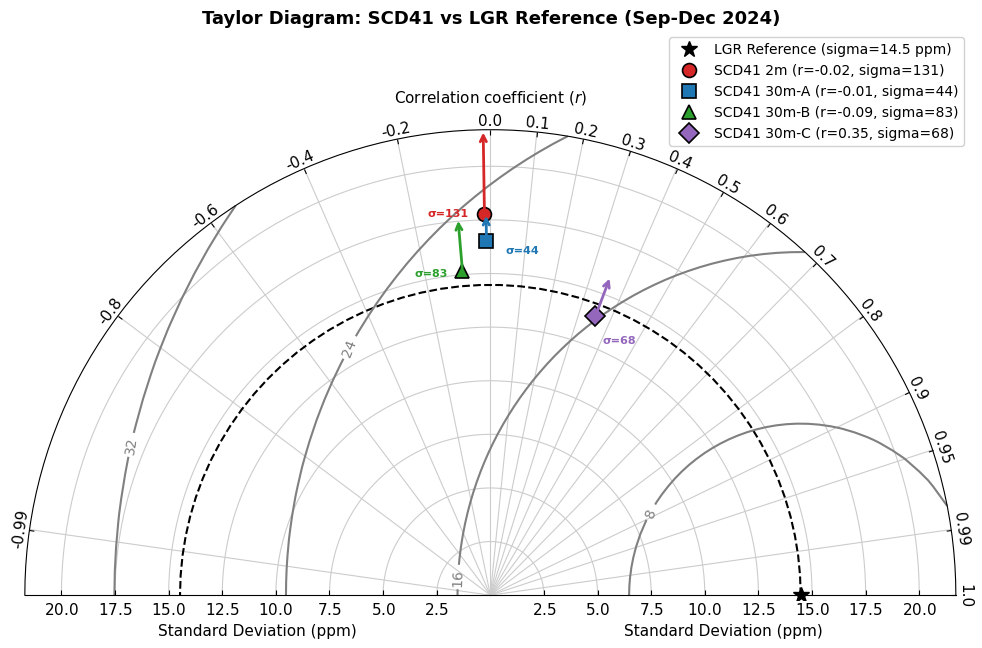

In [55]:
import pandas as pd

plt.style.use('default')
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
    'font.size': 11,
})

# --- paths ---------------------------------------------------
MERGED_CSV = 'output/merged/csv/SMEAR_EE_CO2_merged.csv'

ref_col = 'lgr_30m_CO2_dry_mean'
sensors = {
    'SCD41 2m':    'co2_sct1_2m_co2_mean',
    'SCD41 30m-A': 'co2_30m_a_co2_mean',
    'SCD41 30m-B': 'co2_30m_b_co2_mean',
    'SCD41 30m-C': 'co2_30m_c_co2_mean',
}

# --- load & stats --------------------------------------------
merged = pd.read_csv(MERGED_CSV, parse_dates=['timestamp'], low_memory=False)


def calc_taylor_stats(ref, test):
    valid = ref.notna() & test.notna()
    if valid.sum() < 10:
        return None
    r, t = ref[valid].values, test[valid].values
    return {
        'std':   np.std(t, ddof=1),
        'corr':  np.corrcoef(r, t)[0, 1],
        'crmsd': np.sqrt(np.mean((t - t.mean() - (r - r.mean()))**2)),
        'n':     int(valid.sum()),
    }


ref_std = float(merged[ref_col].std(ddof=1))
stats = {
    name: calc_taylor_stats(merged[ref_col], merged[col])
    for name, col in sensors.items()
}
stats = {k: v for k, v in stats.items() if v is not None}

# --- print summary -------------------------------------------
print(f"REF  sigma = {ref_std:.2f} ppm")
for name, s in stats.items():
    print(f"{name:16s}  sigma={s['std']:7.2f}  r={s['corr']:.3f}  "
          f"CRMSD={s['crmsd']:7.2f}  n={s['n']}")

# --- plot (auto-detects quadrant vs semicircle) --------------
colours = ['#d62728', '#1f77b4', '#2ca02c', '#9467bd']
markers = ['o', 's', '^', 'D']

fig = plt.figure(figsize=(10, 7))

dia = TaylorDiagram.from_stats(
    ref_std,
    correlations=[s['corr'] for s in stats.values()],
    fig=fig, rect=111,
    label=f'LGR Reference (sigma={ref_std:.1f} ppm)',
)

plt.clabel(dia.add_contours(colors='0.5'), inline=True, fontsize=10)

for i, (name, s) in enumerate(stats.items()):
    common_kw = dict(
        label=f"{name} (r={s['corr']:.2f}, sigma={s['std']:.0f})",
        marker=markers[i],
        color=colours[i],
        markersize=10,
        markeredgecolor='black',
        markeredgewidth=1.2,
    )

    if s['std'] > dia.smax * 0.95:
        dia.queue_offchart(s['std'], s['corr'], **common_kw)
    else:
        dia.add_sample(s['std'], s['corr'], linestyle='None', **common_kw)

# Draw all off-chart arrows with proportional lengths
dia.flush_offchart()

fig.legend(
    dia.samplePoints,
    [p.get_label() for p in dia.samplePoints],
    numpoints=1,
    loc='upper right',
    bbox_to_anchor=(0.98, 0.95),
    frameon=True, framealpha=0.9, fontsize=10,
)

fig.suptitle('Taylor Diagram: SCD41 vs LGR Reference (Sep-Dec 2024)',
             fontweight='bold', fontsize=13)
plt.tight_layout()
# plt.savefig('taylor_diagram.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

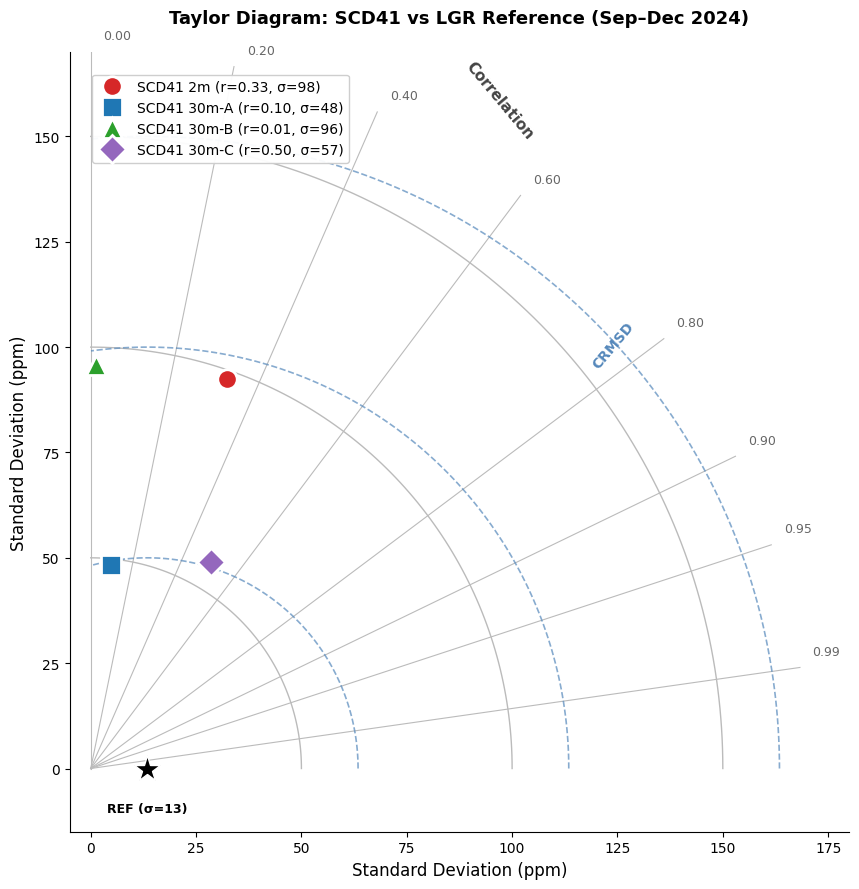

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load merged data
merged = pd.read_csv('output/merged/csv/SMEAR_EE_CO2_merged.csv', parse_dates=['timestamp'], low_memory=False)

# Reference and sensors
ref_col = 'lgr_30m_CO2_dry_mean'
sensors = {
    'SCD41 2m': 'co2_sct1_2m_co2_mean',
    'SCD41 30m-A': 'co2_30m_a_co2_mean',
    'SCD41 30m-B': 'co2_30m_b_co2_mean',
    'SCD41 30m-C': 'co2_30m_c_co2_mean',
}

# Calculate statistics
def calc_taylor_stats(ref, test):
    valid = ref.notna() & test.notna()
    if valid.sum() < 10:
        return None
    r, t = ref[valid].values, test[valid].values
    return {
        'std': np.std(t, ddof=1),
        'corr': np.corrcoef(r, t)[0, 1],
        'crmsd': np.sqrt(np.mean((t - t.mean() - (r - r.mean()))**2)),
        'n': valid.sum()
    }

ref_std = merged[ref_col].std()
stats = {name: calc_taylor_stats(merged[ref_col], merged[col]) 
         for name, col in sensors.items()}
stats = {k: v for k, v in stats.items() if v is not None}

# ============ CLEAN TAYLOR DIAGRAM ============
fig, ax = plt.subplots(figsize=(10, 9))

def polar_to_cart(std, corr):
    theta = np.arccos(np.clip(corr, -1, 1))
    return std * np.cos(theta), std * np.sin(theta)

smax = 170

# 1. Standard deviation arcs (from origin) - SOLID GRAY
for std_val in [50, 100, 150]:
    theta = np.linspace(0, np.pi/2, 100)
    ax.plot(std_val * np.cos(theta), std_val * np.sin(theta), 
            '-', color='#bbbbbb', linewidth=1, zorder=1)

# 2. Correlation lines (from origin) - SOLID GRAY
for corr in [0.0, 0.2, 0.4, 0.6, 0.8, 0.9, 0.95, 0.99]:
    theta = np.arccos(corr)
    x_end, y_end = smax * np.cos(theta), smax * np.sin(theta)
    ax.plot([0, x_end], [0, y_end], '-', color='#bbbbbb', linewidth=0.8, zorder=1)
    # Label at end
    ax.text(x_end + 3, y_end + 3, f'{corr:.2f}', fontsize=9, color='#666666', ha='left')

# 3. RMSD contours (from REFERENCE point) - DASHED BLUE
ref_x = ref_std
for rmsd in [50, 100, 150]:
    theta = np.linspace(0, np.pi, 200)
    x = ref_x + rmsd * np.cos(theta)
    y = rmsd * np.sin(theta)
    valid = (y >= 0) & (x >= 0) & (x <= smax) & (y <= smax)
    if valid.any():
        ax.plot(x[valid], y[valid], '--', color='#5588bb', linewidth=1.2, 
                alpha=0.7, zorder=2)

# 4. Reference point
ax.plot(ref_std, 0, 'k*', markersize=20, zorder=10, markeredgecolor='white', markeredgewidth=1)
ax.text(ref_std, -8, f'REF (σ={ref_std:.0f})', fontsize=9, ha='center', va='top', fontweight='bold')

# 5. Sensor points
colors = ['#d62728', '#1f77b4', '#2ca02c', '#9467bd']
markers = ['o', 's', '^', 'D']

for i, (name, s) in enumerate(stats.items()):
    x, y = polar_to_cart(s['std'], s['corr'])
    ax.plot(x, y, marker=markers[i], color=colors[i], 
            markersize=14, markeredgecolor='white', markeredgewidth=2,
            linestyle='', zorder=5, 
            label=f"{name} (r={s['corr']:.2f}, σ={s['std']:.0f})")

# Axes
ax.set_xlim(-5, smax + 10)
ax.set_ylim(-15, smax)
ax.set_aspect('equal')
ax.set_xlabel('Standard Deviation (ppm)', fontsize=12)
ax.set_ylabel('Standard Deviation (ppm)', fontsize=12)

# Labels - positioned to avoid overlap
ax.text(smax * 0.52, smax * 0.88, 'Correlation', fontsize=11, fontweight='bold',
        color='#444444', rotation=-50)
ax.text(ref_x + 105, 95, 'CRMSD', fontsize=10, color='#5588bb', fontweight='bold',
        rotation=50)

# Title
ax.set_title('Taylor Diagram: SCD41 vs LGR Reference (Sep–Dec 2024)\n', 
             fontsize=13, fontweight='bold')

# Legend - moved to upper left to avoid correlation labels
ax.legend(loc='upper left', frameon=True, framealpha=0.95, fontsize=10,
          bbox_to_anchor=(0.02, 0.98))

# Remove box
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('output/plots/taylor_diagram.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.savefig('output/plots/taylor_diagram.pdf', bbox_inches='tight')
plt.show()

In [ ]:
# from src.taylor_diagram_custom import TaylorPlotter

# plotter = TaylorPlotter(output_dir=Path("output/plots"))

# # Simple: all sensors
# fig = plotter.plot_from_config(
#     config,
#     title="Taylor Diagram: SCD41 Sensors vs LGR Reference",
#     filename="taylor_all_sensors.png"
# )

# # Selective: only 30m sensors
# fig = plotter.plot_from_config(
#     config,
#     test_sensor_ids=['CO2_30M_A', 'CO2_30M_B', 'CO2_30M_C'],
#     title="Taylor Diagram: 30m Height Sensors",
#     filename="taylor_30m_only.png"
# )

from src.visualization import TaylorDiagram

taylor = TaylorDiagram(config.output_dir / "plots")
taylor.plot_from_config(config, normalize=True)